<a href="https://colab.research.google.com/github/Eugenia311/analisis-vinted/blob/main/analisis_vinted.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de mis ventas en Vinted

Análisis de 20 artículos que he publicado en Vinted (octubre-noviembre de 2026), registrados por mí misma en una hoja de cálculo.

**Objetivo:** descubrir qué factores influyen en que un artículo se venda (precio, estado, marca, visibilidad) para optimizar mis ventas. Es la primera fase de un proyecto más amplio: en la siguiente, construiré un agente de IA que me ayude a redactar anuncios y sugerir precios a partir de estos datos.

**Herramientas:** Python (pandas, matplotlib) en Google Colab, con Claude como apoyo para el aprendizaje.

In [13]:
from google.colab import files
subido = files.upload()

Saving registro_vinted.xlsx to registro_vinted (2).xlsx


In [1]:
import pandas as pd

df = pd.read_excel("registro_vinted.xlsx", sheet_name="articulos")
df = df.dropna(how="all")   # quita las filas vacías
df.head(20)

,fecha_publicacion,categoria,marca,estado,precio_inicial,precio_final,fecha_venta,visitas,favoritos
0,2026-10-05,Zapatillas,Fila,bueno,12,12.00,2026-10-05,97,14
1,2026-10-05,Panificadora,Silvercrest,bueno,25,22.00,2026-10-06,109,25
2,2026-10-05,Fular,Sfera,nuevo con etiquetas,4,2.75,2026-10-26,40,7
3,2026-10-05,Fular,Parfois,nuevo con etiquetas,3,2.00,2026-10-26,18,0
4,2026-10-06,Blazer americana,Lefties,bueno,10,10.00,2026-10-07,112,14
5,2026-10-19,Falda,Stradivarius,nuevo con etiquetas,12,10.00,2026-10-23,22,10
6,2026-10-19,Pantalón de pijama,Zara,nuevo con etiquetas,10,10.00,2026-11-02,244,20
7,2026-10-19,Zapatos de piel,Creazioni di Varese,nuevo con etiquetas,25,20.00,2026-10-20,153,12
8,2026-10-19,Sabana bajera,Primark,nuevo con etiquetas,4,4.00,2026-10-19,17,4
9,2026-10-19,Cinturón fajín,Zara,nuevo con etiquetas,12,9.00,2026-10-26,121,18


In [4]:
columnas_texto = ["categoria", "marca", "estado"]

for col in columnas_texto:
    df[col] = df[col].str.strip()

df["categoria"].unique()

array(['Zapatillas', 'Panificadora', 'Fular', 'Blazer americana', 'Falda',
       'Pantalón de pijama', 'Zapatos de piel', 'Sabana bajera',
       'Cinturón fajín', 'Chaqueta cortavientos', 'Sudadera manta',
       'Pack collares', 'Medias térmicas', 'Sandalias verdes',
       'Chaquetón', 'Abrigo de pelo', 'Falda plisada', 'Bufanda',
       'Pantalon palazzo'], dtype=object)

In [5]:
grupos = {
    "Zapatillas": "calzado",
    "Zapatos de piel": "calzado",
    "Sandalias verdes": "calzado",
    "Blazer americana": "ropa",
    "Falda": "ropa",
    "Falda plisada": "ropa",
    "Pantalón de pijama": "ropa",
    "Pantalon palazzo": "ropa",
    "Chaqueta cortavientos": "ropa",
    "Chaquetón": "ropa",
    "Abrigo de pelo": "ropa",
    "Sudadera manta": "ropa",
    "Medias térmicas": "ropa",
    "Fular": "accesorios",
    "Bufanda": "accesorios",
    "Cinturón fajín": "accesorios",
    "Pack collares": "accesorios",
    "Panificadora": "hogar",
    "Sabana bajera": "hogar",
}

df["grupo"] = df["categoria"].map(grupos)
df["grupo"].value_counts()


,count
grupo,
ropa,10
accesorios,5
calzado,3
hogar,2


In [6]:
df["vendido"] = df["precio_final"].notna()
df["dias_hasta_venta"] = (df["fecha_venta"] - df["fecha_publicacion"]).dt.days

df[["categoria", "vendido", "dias_hasta_venta"]]


,categoria,vendido,dias_hasta_venta
0,Zapatillas,True,0.0
1,Panificadora,True,1.0
2,Fular,True,21.0
3,Fular,True,21.0
4,Blazer americana,True,1.0
5,Falda,True,4.0
6,Pantalón de pijama,True,14.0
7,Zapatos de piel,True,1.0
8,Sabana bajera,True,0.0
9,Cinturón fajín,True,7.0


In [7]:
df.groupby("vendido")[["precio_inicial", "visitas", "favoritos"]].mean().round(1)

,precio_inicial,visitas,favoritos
vendido,,,
False,9.3,16.5,1.5
True,10.3,84.0,11.8


In [8]:
df.groupby("estado")["vendido"].agg(["sum", "count"])


,sum,count
estado,,
bueno,3,4
muy bueno,3,7
nuevo con etiquetas,8,9


In [9]:
df.groupby("estado")["vendido"].mean().round(2)

,vendido
estado,
bueno,0.75
muy bueno,0.43
nuevo con etiquetas,0.89


In [10]:
inditex = ["Zara", "Stradivarius", "Lefties"]

df["es_inditex"] = df["marca"].isin(inditex)
df.groupby("es_inditex")["vendido"].agg(["sum", "count", "mean"]).round(2)

,sum,count,mean
es_inditex,,,
False,10,15,0.67
True,4,5,0.80


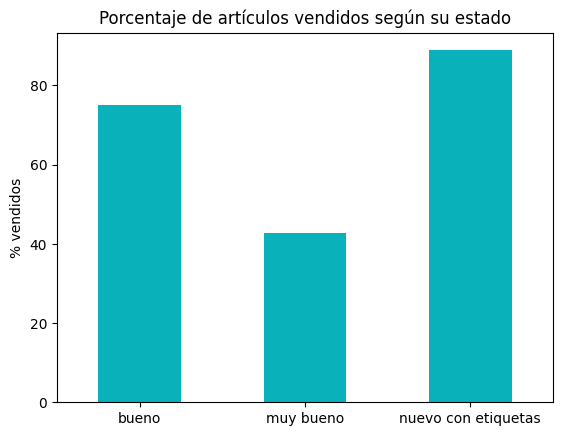

In [11]:
import matplotlib.pyplot as plt

ventas_estado = df.groupby("estado")["vendido"].mean() * 100

ventas_estado.plot(kind="bar", color="#09B1BA")
plt.title("Porcentaje de artículos vendidos según su estado")
plt.ylabel("% vendidos")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

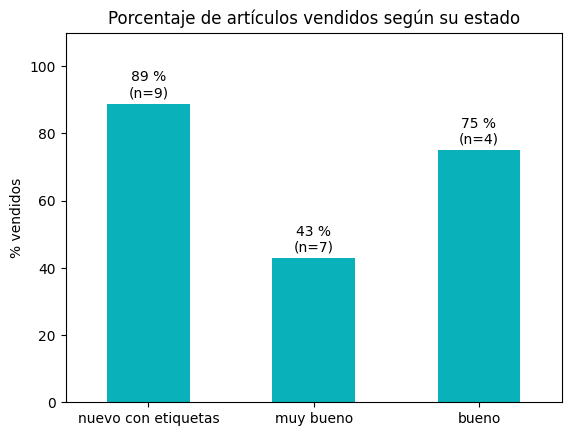

In [12]:
import matplotlib.pyplot as plt

orden = ["nuevo con etiquetas", "muy bueno", "bueno"]

resumen = df.groupby("estado")["vendido"].agg(["mean", "count"]).loc[orden]
resumen["mean"] = resumen["mean"] * 100

ax = resumen["mean"].plot(kind="bar", color="#09B1BA")

for i, (pct, n) in enumerate(zip(resumen["mean"], resumen["count"])):
    ax.text(i, pct + 2, f"{pct:.0f} %\n(n={n})", ha="center")

plt.title("Porcentaje de artículos vendidos según su estado")
plt.ylabel("% vendidos")
plt.xlabel("")
plt.ylim(0, 110)
plt.xticks(rotation=0)
plt.show()

## Conclusiones

**Datos:** 20 artículos publicados en Vinted entre octubre y noviembre de 2026 (14 vendidos, 6 sin vender).

**Qué he encontrado:**
- El precio no explica qué se vende: los no vendidos cuestan casi lo mismo (9,3 € frente a 10,3 €). La gran diferencia está en la visibilidad: los vendidos tienen unas 5 veces más visitas (84 frente a 16,5 de media).
- Lo nuevo con etiquetas es lo que mejor se vende: 89 %, frente a 75 % en «bueno» y 43 % en «muy bueno».
- Las marcas de Inditex (Zara, Stradivarius, Lefties) se venden algo más: 80 % frente a 67 %.

**Limitaciones:**
- La muestra es muy pequeña (sólo 5 artículos de Inditex), así que es una suposición, no podemos afirmarlo como conclusión.
- Estado y marca pueden estar mezclados: varios artículos de Inditex eran además nuevos con etiquetas.
- Los datos cubren solo un mes, por lo que la temporada puede influir.

**Próximos pasos:**
- Seguir registrando ventas para comprobar si lo que no se vende está fuera de temporada (por ejemplo, las sandalias en otoño).